# CalcFADC: TPC の FADC 波形から電荷を求める

TPC の各 FADC ch(アノード 12 ch、カソード 12 ch。1 ch = 32 ストリップの和)の波形から、
ベースラインを差し引いた電荷を求めます。SMILE_tool_box の `CalcFADC` と同じ手順です。

1. 最初の `base_window` サンプルの平均をベースラインとする
2. サンプル `Range_min` ≤ i < `Range_max` のうち、波形 − ベースライン > `threshold` のサンプルだけを足す
3. 該当サンプルがなければ電荷 = −100(ヒットなし)
4. `ADC_to_mV × Clock_to_nsec / 50` を掛けて単位を変換する

求めた電荷は `TPC_Calibration` が反跳電子のエネルギーに変換します。

### パラメータ

| パラメータ | 値 | 意味 |
|---|---|---|
| `base_window` | 30 | ベースラインを求めるサンプル数 |
| `threshold` | 20 | 足し込むサンプルの閾値 [ADC] |
| `Range_min`, `Range_max` | 30, 500 | 積分するサンプル範囲 |
| `ADC_to_mV`, `Clock_to_nsec` | 2, 20 | 単位変換 |

In [1]:
import sys, subprocess
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import ROOT
ROOT.gROOT.SetBatch(True)

# リポジトリの場所、チェーンの実行スクリプト、設定ファイル(config/*.json)の読み込み
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_script" / "run_chain.py").exists())
RUN_CHAIN = REPO / "run_script" / "run_chain.py"
sys.path.insert(0, str(REPO / "config"))
import ericanext_config as ec
CACHE = REPO / "tutorials_caldata" / "cache"   # チェーンの出力の置き場(チュートリアル間で共有)
CACHE.mkdir(exist_ok=True)

def vec(column):
    """RDataFrame.AsNumpy() の配列型の列 -> 2 次元の numpy 配列"""
    return np.stack([np.asarray(v) for v in column])

## 1. データの準備

データ(20190701 の較正データ **Per02**)の入手方法と置き場所は、
**[1_DataIO のノートブック](../../DataIO_example.ipynb) の「1. データの準備」**を見てください。
NAS を読める計算機では、ここでは何もする必要はありません。

下のセルで、設定ファイル `config/smile2p_20190701_Per02.json` が指すデータが見つかるかだけ確認します
(`MISSING` と出たら 1_DataIO の 1 節を見てください)。

In [2]:
CONFIG = "smile2p_20190701_Per02"
cfg = ec.load(CONFIG)
print("data_top:", ec.data_top())
for path in [cfg["parameters"]["ReadData"]["data_dir"], cfg["parameters"]["HA_Calc"]["parameter_dir"]]:
    print("OK     " if Path(path).is_dir() else "MISSING", path)

data_top: /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/calibration_data
OK      /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/calibration_data/sm2+_cal_rawdata/20190701_Per02
OK      /mnt/nas_eureka/onoda/EricaNext_try_data/SMILE2+/calibration_data/param/20190528


## 2. 生データツリーを作る

モジュールの出力ファイルには図(ヒストグラム)を保存せず、TTree だけを書きます。
処理の中身を確かめる図は、`ReadData → RawTreeWriter` で作る**生データツリー**(`RawTreeWriter/raw`)から描きます。
中身は `../8_RawTreeWriter/` を参照してください。ここでは Per02 の先頭 5000 イベントを使います。

ターミナル(コマンドプロンプト)では、リポジトリの `run_script` ディレクトリで次を実行するのと同じです。

```bash
cd EricaNext_try/run_script
python3 run_chain.py smile2p_20190701_Per02 -o Per02_raw_5000.root -n 5000 --raw --compression 505
```

| 引数 | 意味 |
|---|---|
| `smile2p_20190701_Per02` | 設定ファイル `config/smile2p_20190701_Per02.json`(データの場所と各モジュールのパラメータ) |
| `-o Per02_raw_5000.root` | 出力ファイル |
| `-n 5000` | 先頭 5000 イベントだけ処理する(省略すると全イベント) |
| `--raw` | `ReadData → RawTreeWriter` だけを実行し、生データツリーを書く(再構成はしない) |
| `--compression 505` | ROOT の圧縮を zstd(レベル 5)にする。既定の圧縮より約 2 割小さくなる |

下のセルは同じコマンドを Python から実行しています(`sys.executable` は今のカーネルの python3、
`RUN_CHAIN` は `run_chain.py` のパス、`CONFIG` は設定名)。出力が既にあれば再実行しません。

In [3]:
# ReadData -> RawTreeWriter だけを実行して生データツリーを作る(先頭 5000 イベント、zstd 圧縮)
RAW = CACHE / "Per02_raw_5000.root"
cmd = [sys.executable, str(RUN_CHAIN), CONFIG, "-o", str(RAW), "-n", "5000", "--raw", "--compression", "505"]
print(" ".join(cmd))
if not RAW.exists():
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stdout[-3000:], r.stderr[-3000:])
    r.check_returncode()

# ボード ID の一覧(別ツリー run_info に 1 行だけ入っている)
info = ROOT.RDataFrame("RawTreeWriter/run_info", str(RAW)).AsNumpy(["anode_ids", "cathode_ids", "ha_ids"])
HA_IDS = [int(x) for x in info["ha_ids"][0]]
print("HA modules:", HA_IDS)

/usr/bin/python3 /home/onoda/ANLNext/EricaNext_try/run_script/run_chain.py smile2p_20190701_Per02 -o /home/onoda/ANLNext/EricaNext_try/tutorials_caldata/cache/Per02_raw_5000.root -n 5000 --raw --compression 505


HA modules: [1, 2, 3, 7, 8, 9, 13, 14, 15, 19, 20, 21, 25, 26, 27, 31, 32, 33]


## 3. 生データツリーの波形から CalcFADC と同じ計算をする

下の関数は CalcFADC と同じ計算です(チェーン内の CalcFADC の値と完全に一致することを確認済み)。
パラメータを変えて、電荷がどう変わるかを試せます。

In [4]:
def calc_fadc(w, base_window=30, threshold=20., range_min=30, range_max=500, adc_to_mV=2., clock_to_nsec=20.):
    """w: [n_ch, 512] -> (baseline[n_ch], charge[n_ch])  (SMILE_tool_box CalcFADC)"""
    base = w[:, :base_window].sum(1) / base_window
    d = w[:, range_min:range_max] - base[:, None]
    over = d > threshold
    q = np.where(over.any(1), np.where(over, d, 0.).sum(1), -100.)
    return base, q * adc_to_mV * clock_to_nsec / 50.

rows = []   # (ch, baseline, charge with threshold 20, 10, 40)
d = ROOT.RDataFrame("RawTreeWriter/raw", str(RAW)).AsNumpy(["fadc_ch", "fadc_wave"])
for ch, w in zip(d["fadc_ch"], d["fadc_wave"]):
    ch = np.asarray(ch); w = np.asarray(w, float).reshape(len(ch), 512)   # 保存した ch × 512 サンプル
    base, q20 = calc_fadc(w)
    _, q10 = calc_fadc(w, threshold=10.)
    _, q40 = calc_fadc(w, threshold=40.)
    rows.append(np.column_stack([ch, base, q20, q10, q40]))
r = np.concatenate(rows)
print(r.shape[0], "channel waveforms")

57744 channel waveforms


## 4. ベースラインと電荷

ch ごとのベースラインの分布と電荷の分布です(縦軸が ch 番号、0–11 アノード、12–23 カソード)。

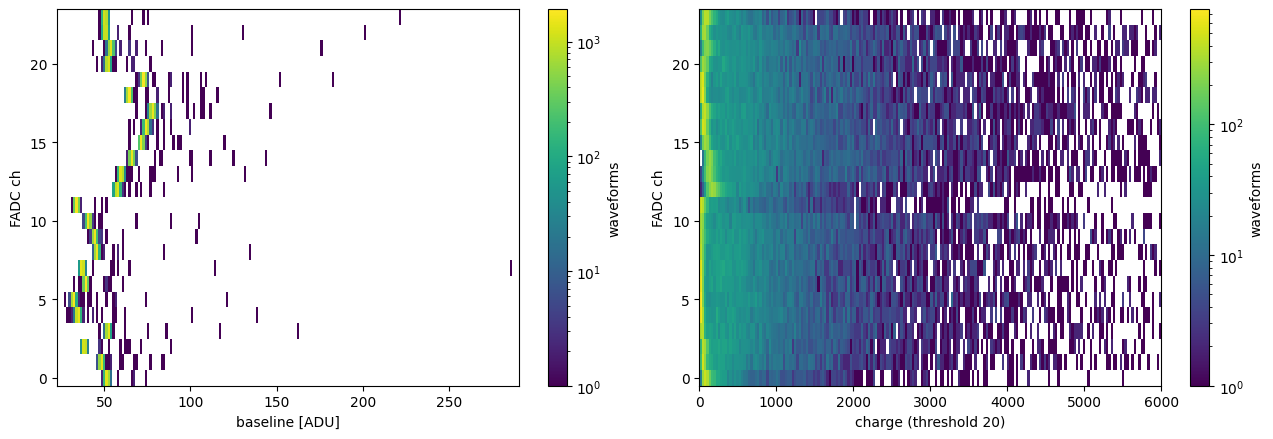

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
h = ax[0].hist2d(r[:, 1], r[:, 0], bins=[200, 24], range=[[r[:, 1].min() - 5, r[:, 1].max() + 5], [-0.5, 23.5]], cmin=1, norm="log")
fig.colorbar(h[3], ax=ax[0], label="waveforms")
ax[0].set_xlabel("baseline [ADU]"); ax[0].set_ylabel("FADC ch")
ok = r[:, 2] > 0
h = ax[1].hist2d(r[ok, 2], r[ok, 0], bins=[200, 24], range=[[0, 6000], [-0.5, 23.5]], cmin=1, norm="log")
fig.colorbar(h[3], ax=ax[1], label="waveforms")
ax[1].set_xlabel("charge (threshold 20)"); ax[1].set_ylabel("FADC ch")
fig.tight_layout(); plt.show()

閾値を変えると電荷の分布がどう変わるか(全 ch):

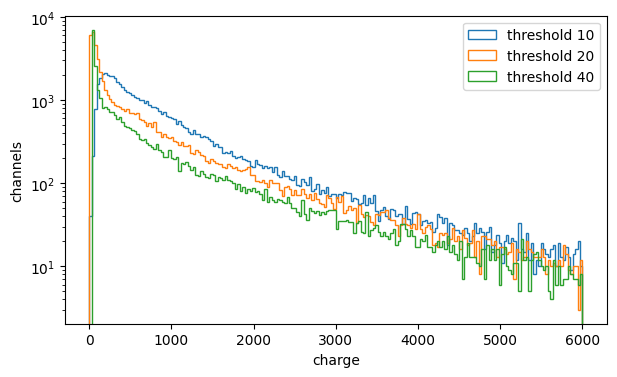

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
for col, th in [(3, 10), (2, 20), (4, 40)]:
    q = r[:, col]; ax.hist(q[q > 0], bins=200, range=(0, 6000), histtype="step", label=f"threshold {th}")
ax.set_yscale("log"); ax.set_xlabel("charge"); ax.set_ylabel("channels"); ax.legend()
plt.show()